In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1. Load a different Kaggle dataset (California Housing)**

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.sample(n=2000, random_state=42) # Taking a sample for faster K-Means convergence

print("Dataset Head:")
print(df.head())

Dataset Head:
       MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
20046  1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06   
3024   2.5313      30.0  5.039384   1.193493      1565.0  2.679795     35.14   
15663  3.4801      52.0  3.977155   1.185877      1310.0  1.360332     37.80   
20484  5.7376      17.0  6.163636   1.020202      1705.0  3.444444     34.28   
9814   3.7250      34.0  5.492991   1.028037      1063.0  2.483645     36.62   

       Longitude  MedHouseVal  
20046    -119.01      0.47700  
3024     -119.46      0.45800  
15663    -122.44      5.00001  
20484    -118.72      2.18600  
9814     -121.93      2.78000  


**selecting few numerical features for clustering**

In [3]:
features = ['MedInc', 'AveRooms', 'AveOccup', 'HouseAge']
X = df[features].values

**Feature scaling since this is a distance based algorithm**

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**k values**

In [5]:
k_values = [1, 3, 5]

inertia_results = []
silhouette_results = []

**evaluate for each k**

In [6]:
for k in k_values:
    if k == 1:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X_scaled)
        inertia = model.inertia_
        
        inertia_results.append(inertia)
        silhouette_results.append(None)
        
        print(f"\nK Value: {k}")
        print(f"Inertia: {inertia:.4f}")
        print("Silhouette Score: Not applicable")
    else:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X_scaled)
        
        labels = model.labels_
        inertia = model.inertia_
        score = silhouette_score(X_scaled, labels)
        
        inertia_results.append(inertia)
        silhouette_results.append(score)
        
        print(f"\nK Value: {k}")
        print(f"Inertia: {inertia:.4f}")
        print(f"Silhouette Score: {score:.4f}")


K Value: 1
Inertia: 8000.0000
Silhouette Score: Not applicable

K Value: 3
Inertia: 4566.9574
Silhouette Score: 0.3338

K Value: 5
Inertia: 2660.1262
Silhouette Score: 0.3223


In [7]:
results = pd.DataFrame({
    "K Value": k_values,
    "Inertia": inertia_results,
    "Silhouette Score": silhouette_results
})

print("\nComparison Results:")
print(results)


Comparison Results:
   K Value      Inertia  Silhouette Score
0        1  8000.000000               NaN
1        3  4566.957440          0.333758
2        5  2660.126241          0.322339


**Visualization**

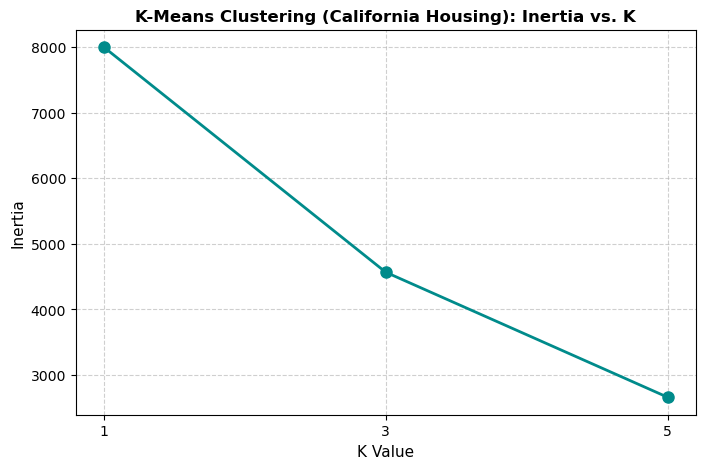

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_results, marker="o", linestyle="-", color="darkcyan", linewidth=2, markersize=8)

plt.xlabel("K Value", fontsize=11)
plt.ylabel("Inertia", fontsize=11)
plt.title("K-Means Clustering (California Housing): Inertia vs. K", fontsize=12, fontweight='bold')

plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()